# CS5 - Saturation-Model Selection & Sensitivity (well 30/6-5)

**Petrophys Case Studies - a decision-focused project lesson**

## Part 1 - The brief

> **"Which water-saturation model should we trust in this shaly sand, and how much
> does the choice move net pay and hydrocarbon pore volume (HCPV)? Quantify the
> sensitivity of the answer to both the *model* and the *parameter* assumptions."**

A subsurface team has a shaly-sand reservoir on the North Sea well **30/6-5**. The
gross rock volume is fixed by seismic; the volumetric uncertainty that the team
controls comes almost entirely from the **petrophysical water saturation (Sw)**. In a
*clean* sand Archie's equation is sufficient, but this interval carries dispersed clay,
and clay adds an extra conductive path that Archie does **not** account for - so Archie
reads Sw too high and undercounts pay. Several shaly-sand corrections exist
(Simandoux, Indonesia, and the regional North Sea and Nigeria forms - plus the
lab-data Waxman-Smits / Dual-Water family when CEC and SCAL exist) and they
disagree.

The deliverable of this lesson is **not** a single number. It is:

1. A **decision table** - the five Sw models side by side, each with mean Sw, net pay,
   and a hydrocarbon-pore-thickness (HCPT) index.
2. A **sensitivity / tornado analysis** - how much net pay and HCPT move when we sweep
   the key uncertain inputs (Rw, m, n, Vcl cutoff).
3. A **reasoned recommendation** - which model to trust here and why, with an
   **uncertainty band** on HCPV implied by the sensitivity.

This case study reuses the fundamentals taught in tutorial 07 (saturation) but is
oriented toward a *decision under uncertainty*, not toward teaching the equations.

**What you will learn**

- How to run several saturation models on one interval with a common parameter set.
- How to turn model differences into a decision table of net pay and HCPT.
- How to build a one-at-a-time sensitivity (tornado) and read which assumption to measure first.
- How to quote an uncertainty band instead of a single number.

**Prerequisites.** Lesson 07 (water saturation models), lesson 09 (net pay; it also reconciles
this well's Rw) and case study CS1 (the full evaluation of the same well). The base install is
enough.


## Part 2 - The well & the data

**Well 30/6-5** is a GeoLink North Sea clastic well (depths in metres). It penetrates
two sand packages relevant to us:

| Interval | Depth (m) | Fluid | Role in this study |
|---|---|---|---|
| Brent sands (`BAAT GP.` in the bundled tops) | 2841 - 2958 | hydrocarbon-bearing | **the reservoir** we evaluate |
| Statfjord sands | 3223 - 3556 | water leg | **Pickett calibration** (Sw~1; the regression still fails, and 4.2 shows why) |

The two-interval design is deliberate: a Pickett plot can only pin down the Archie
parameters (m, and via the intercept Rw) from a **water-bearing** zone where Sw is known
to be ~1. We use the deeper Statfjord water leg for that, then carry the parameters up
into the hydrocarbon interval. The water-leg premise is solid here - CS1's formation
roll-up finds only scattered, low net-to-gross pay flags in the Statfjord and does not treat
it as a target, and the NPD records no discovery there - but section 4.2 shows that a
least-squares Pickett *regression* fails on this leg anyway, for reasons worth understanding.

**What we have:** GR, RHOB, NPHI, deep resistivity (RDEP), plus core (PHIC, SWC).
**What we are missing:** no directly usable Rw measurement (the header value needs the
reconciliation described in 4.2), no CEC/Qv lab data, no independent m/n from SCAL.
Every one of those becomes an *assumption* that we will flag and then stress-test in the
sensitivity analysis - which is exactly the point of the brief.

A scope call on that core, stated explicitly rather than quietly dropped: the well carries
core SWC points inside the evaluated reservoir slice (counted in the next cell). They exist,
they sit in the interval, and a production study would benchmark the five Sw models against
them - with the standard caveat that core saturations from non-preserved core are altered by
mud-filtrate flushing and fluid loss during recovery. This study stays **log-only** by scope,
so the core saturations are acknowledged, not used.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys as pp
from petrophys.evaluation import (
    STANDARD_CUTOFFS, compare_saturation_models, parameter_sensitivity,
)
from petrophys.interpretation.clay_volume import vcl_from_gr
from petrophys.interpretation.porosity import (
    density_porosity, total_porosity, effective_porosity,
)
from petrophys.interpretation.electrical.cementation import pickett_analysis

print("petrophys", pp.__version__)

well = pp.read(pp.sample("30_6-5"))
print("well :", well.name)
print("field:", well.header.field)
print("depth: {:.1f} - {:.1f} {} ({} samples, step {:.3f} {})".format(
    well.top, well.bottom, well.depth_unit, well.n_samples, well.step, well.depth_unit))
print("curves used:", ", ".join(c for c in ["GR", "RHOB", "NPHI", "RDEP", "PHIC", "SWC"]
                                if well.has_curve(c)))

# Core SWC inside the Brent reservoir slice. This LAS stores SWC in percent although
# the curve is labelled 'frac' (see CS1), so we report it in percent here.
swc = well.get("SWC")
in_res = (well.depth >= 2841.0) & (well.depth <= 2958.0) & np.isfinite(swc.data)
print("core SWC in 2841-2958 m: {} points, {:.0f}-{:.0f} % (mean {:.0f} %; labelled '{}')".format(
    in_res.sum(), np.nanmin(swc.data[in_res]), np.nanmax(swc.data[in_res]),
    np.nanmean(swc.data[in_res]), swc.unit))

petrophys 3.0.0


well : 30/6-5
field: OSEBERG ØST
depth: 176.6 - 3556.1 m (22176 samples, step 0.152 m)
curves used: GR, RHOB, NPHI, RDEP, PHIC, SWC
core SWC in 2841-2958 m: 74 points, 14-85 % (mean 48 %; labelled 'frac')


## Part 3 - Workflow plan

The interpretation chain, and *why* in this order:

1. **Slice the two intervals** - reservoir (Brent) and water leg (Statfjord).
2. **Vcl from GR** (Larionov, older rocks) - the shale volume is the single input that
   the shaly-sand models need and that Archie ignores.
3. **Porosity** - density porosity -> total porosity (N/D) -> **effective** porosity via
   Vcl. Effective PHIE feeds every model in the comparison; PHIT is kept on the plots
   so the clay-bound water volume stays visible.
4. **Pickett plot on the water leg** - derive an illustrative *m* and *Rw*. We will see
   the log-only Pickett is poorly constrained here and make a *judgement call* on the
   base-case m/n - a realistic petrophysical decision.
5. **Run all five Sw models** over the reservoir with one common parameter set.
6. **Decision table** - mean Sw, net pay, HCPT per model under a fixed cutoff set.
7. **Parameter sensitivity** - sweep Rw, m, n and the Vcl cutoff; build a tornado.
8. **Recommendation** - pick a model, quote an HCPV uncertainty band.

We keep the calls granular (rather than a single `pp.interpret`) *precisely because*
the deliverable is a controlled sensitivity sweep: we need to vary one assumption at a
time and re-evaluate, which is cleanest with explicit function calls. CS1 shows the
one-call workflow on the same well.


## Part 4 - Execution

### 4.1 Slice the intervals and compute Vcl + porosity

We build a small helper that, given a depth-sliced well, returns Vcl, PHIT and PHIE on a
consistent basis so the reservoir and the water leg are processed identically.

One library behaviour to know when reading the printed GR endpoints: `vcl_from_gr` clamps
the clean anchor to <=20 API and the shale anchor to >=100 API. The cell prints both the raw
interval percentiles and the endpoints actually used inside the Vcl calculation.

In [2]:
RES_TOP, RES_BOT = 2841.0, 2958.0      # Brent sands (hydrocarbon-bearing)
WAT_TOP, WAT_BOT = 3223.0, 3556.0      # Statfjord water leg (Sw ~ 1)

RHO_MA, RHO_FL = 2.65, 1.0             # sandstone matrix, fresh mud filtrate
PHI_CLAY = 0.15                        # clay porosity for PHIE (assumed)

def evaluate_interval(w, top, bot, gr_method="larionov_older"):
    seg = w.depth_slice(top, bot)
    gr   = seg.get("GR").data
    rhob = seg.get("RHOB").data
    nphi = seg.get("NPHI").data
    rt   = seg.get("RDEP").data
    depth = seg.depth
    dz = seg.step
    # GR endpoints from robust percentiles of THIS interval
    gr_min = float(np.nanpercentile(gr, 5))
    gr_max = float(np.nanpercentile(gr, 95))
    vcl  = np.clip(vcl_from_gr(gr, gr_min, gr_max, method=gr_method), 0.0, 1.0)
    phid = density_porosity(rhob, RHO_MA, RHO_FL)
    phit = np.clip(total_porosity(nphi, phid, method="adaptive"), 0.001, 0.45)
    phie = np.clip(effective_porosity(phit, vcl, phi_clay=PHI_CLAY), 0.001, 0.40)
    return dict(depth=depth, dz=dz, gr=gr, rt=rt,
                vcl=vcl, phit=phit, phie=phie,
                gr_min=gr_min, gr_max=gr_max)

res = evaluate_interval(well, RES_TOP, RES_BOT)
wat = evaluate_interval(well, WAT_TOP, WAT_BOT)

for label, top, bot, iv in (("RESERVOIR", RES_TOP, RES_BOT, res), ("WATER LEG", WAT_TOP, WAT_BOT, wat)):
    print("{}  {:.0f}-{:.0f} m  ({} samples, dz={:.4f} m)".format(
        label, top, bot, len(iv["depth"]), iv["dz"]))
    print("  GR endpoints (5/95 pct): {:.1f} / {:.1f} API -> used in Vcl: {:.1f} / {:.1f} API".format(
        iv["gr_min"], iv["gr_max"], min(iv["gr_min"], 20.0), max(iv["gr_max"], 100.0)))
    print("  mean Vcl={:.3f}  PHIT={:.3f}  PHIE={:.3f}".format(
        np.nanmean(iv["vcl"]), np.nanmean(iv["phit"]), np.nanmean(iv["phie"])))

RESERVOIR  2841-2958 m  (768 samples, dz=0.1523 m)
  GR endpoints (5/95 pct): 26.2 / 106.5 API -> used in Vcl: 20.0 / 106.5 API
  mean Vcl=0.356  PHIT=0.193  PHIE=0.139
WATER LEG  3223-3556 m  (2185 samples, dz=0.1523 m)
  GR endpoints (5/95 pct): 42.0 / 135.9 API -> used in Vcl: 20.0 / 135.9 API
  mean Vcl=0.409  PHIT=0.110  PHIE=0.054


#### Reservoir context

The reservoir's mean Vcl (printed above) is well into the shaly-sand range. Archie does not
represent conductive clay and can therefore overestimate water saturation here. The shaly-sand
models provide the relevant sensitivity range.

### 4.2 Pickett plot on the water leg -> illustrative m and Rw

The Pickett plot is `log(Rt)` vs `log(PHI)` for water-bearing points; the slope gives
`-m` and the intercept gives `log(a*Rw)`. We restrict to the cleaner, higher-porosity
Statfjord points (Vcl < 0.30) and call `pickett_analysis`.

**Important caveat, up front:** `pickett_analysis` regresses on log-log data and returns
`n = 2.0` by construction (it fits *m* and the intercept - a*Rw with a=1 assumed; *n* comes from
SCAL, which we do not have). On this real well the water-leg cloud is heterogeneous (variable Rw, mixed
lithology), so the log-only *m* comes out unphysically low with a weak R-squared. We therefore
treat the fitted *m* as a demonstration of the **regression trap** (lesson 07 dissects
it), and take the base-case parameters from the operator's documented evaluation instead.

In [3]:
ap, pk = pickett_analysis(wat["rt"], wat["phie"], vcl=wat["vcl"], vcl_cutoff=0.30)

Rw_pickett = 10.0 ** pk["intercept"]     # intercept = log10(a*Rw), a=1
print("Pickett fit on Statfjord water leg (Vcl<0.30):")
print("  n_points  = {}".format(pk["n_points"]))
print("  m (slope) = {:.3f}".format(pk["m"]))
print("  R-squared = {:.3f}".format(pk["r_squared"]))
print("  intercept = {:.3f}  -> Rw (a=1) = {:.4f} ohm.m".format(
    pk["intercept"], Rw_pickett))
print()
M_RANGE, MIN_R2 = (1.6, 2.1), 0.8        # physical m range; minimum R-squared we would trust
usable = M_RANGE[0] <= pk["m"] <= M_RANGE[1] and pk["r_squared"] >= MIN_R2
print("READ-OUT: m={:.2f} is {} the physical {:.1f}-{:.1f} range and R-squared={:.2f} is {} {:.1f},".format(
    pk["m"], "inside" if M_RANGE[0] <= pk["m"] <= M_RANGE[1] else "outside", *M_RANGE,
    pk["r_squared"], "above" if pk["r_squared"] >= MIN_R2 else "below", MIN_R2))
print("so the log-only fit {} as a rock property.".format("is usable" if usable else "is NOT usable"))

Pickett fit on Statfjord water leg (Vcl<0.30):
  n_points  = 880
  m (slope) = 0.628
  R-squared = 0.600
  intercept = -0.017  -> Rw (a=1) = 0.9614 ohm.m

READ-OUT: m=0.63 is outside the physical 1.6-2.1 range and R-squared=0.60 is below 0.8,
so the log-only fit is NOT usable as a rock property.


#### Pickett-fit caution

The low coefficient of determination means the water-leg point cloud does not
constrain the cementation exponent reliably. Treat the fitted value as a
regression diagnostic, not as a calibrated rock property.


**Why does the fit fail? (diagnosis.)** An *m* far below the physical range together with an
apparent Rw near 1 ohm.m (both printed above) is not just noise - it is the signature of
regressing through a *mixed* cloud: scatter, thin tight hydrocarbon-bearing streaks and the
temperature drift of Rw along the leg all push points up-and-left, which flattens the slope and
inflates the intercept. Lesson 07 dissects exactly this trap on the same interval and shows the
industry alternative: fix m at a plausible value and pick Rw from the **lower envelope** of the
clean cloud - which lands close to the operator's value below. The regression is discarded
either way.

**Base case (documented, not guessed).** The LAS header carries the operator's parameter
block, and lesson 09 reconciles it against the completion-report evaluation: the header
prints `RW = 0.70` with no temperature basis, and the value the operator's evaluation
actually used is **Rw = 0.070 ohm.m at 230 degF** (reservoir temperature), with **a = 0.80,
m = n = 2** - constants that reproduce their zone-by-zone pay table and bracket the NPD's
2907 m OWC (case study 1). We adopt that set as the base case:

- `a = 0.80`, `m = 2.0`, `n = 2.0` (operator evaluation constants)
- `Rw = 0.070` ohm.m at 230 degF. Because that is the reservoir temperature, we apply it directly
  over the 2841-2958 m reservoir without a further temperature correction. (With `pp.interpret`
  you would pass `rw=0.07, rw_meas_temp_f=230`; CS1 does exactly that.)

Documented is not the same as certain - the basis reconciliation, the vintage of the
evaluation and the absence of SCAL all leave real uncertainty, which is exactly what the
tornado in Part 6 sweeps.

In [4]:
# ---- Base-case parameter set (operator-documented; swept in Part 6) ----
BASE = dict(
    Rw   = 0.070,    # ohm.m at 230 degF = reservoir temperature (operator value, lesson 09)
    a    = 0.80,     # tortuosity (operator evaluation constant)
    m    = 2.0,      # cementation exponent (operator evaluation constant)
    n    = 2.0,      # saturation exponent (operator evaluation constant; no SCAL)
    Rcl  = 3.0,      # clay/shale resistivity (ohm.m), from shaly response
)
# ---- Cutoff set for net pay / HCPT: the clastic curriculum standards ----
_clastic = STANDARD_CUTOFFS["clastic"]
CUT = dict(vcl=_clastic["vcl_cutoff"], phie=_clastic["phie_cutoff"], sw=_clastic["sw_cutoff"])

print("Base parameters:", BASE)
print("Cutoffs        :", CUT)

Base parameters: {'Rw': 0.07, 'a': 0.8, 'm': 2.0, 'n': 2.0, 'Rcl': 3.0}
Cutoffs        : {'vcl': 0.4, 'phie': 0.08, 'sw': 0.6}


### 4.3 Run the five field-data saturation models

Model families and what each one is *for*:

| Model | Porosity basis | Clay term | When you reach for it |
|---|---|---|---|
| **Archie** | PHIE | none | clean sand baseline (biased high in shaly rock) |
| **Simandoux** | PHIE | `Vcl/Rcl` (linear) | classic shaly-sand, dispersed clay |
| **Indonesia** (Poupon-Leveaux) | PHIE | `Vcl^(2-Vcl)/Rcl` | laminated/dispersed, high-Vcl robust |
| **North Sea** (regional) | PHIE | `Vsh^1.6/Rtsh` laminated term | North Sea shaly sands - the local convention for this well |
| **Nigeria** (Schlumberger, regional) | PHIE | `Vcl^c` term in sqrt space | Niger-delta-style laminated sands |

All five run on **PHIE** with the clay handled by an explicit Vcl term - no laboratory
inputs required. `compare_saturation_models` (in `petrophys.evaluation`) runs them on one
interval with one parameter set (Rw, the shale resistivity `rsh`, a, m, n) and returns
each model's Sw curve (clipped to 0-1) together with the decision table used in 4.4. The total-porosity, lab-data family (Waxman-Smits, Dual-Water) needs
CEC / Rwb measurements this well does not have, so it is **excluded rather than
guessed** - lesson 07 (section 3b) demonstrates that family and its failure mode on
guessed inputs, and the workflow router behaves the same way: it only selects
Waxman-Smits when `cec` is actually supplied.

In [5]:
rt   = res["rt"]
vcl  = res["vcl"]
phie = res["phie"]
phit = res["phit"]

# The same curves and cutoffs for every model; only the Sw equation changes.
COMMON = dict(rt=rt, phie=phie, vcl=vcl, depth=res["depth"], depth_unit=well.depth_unit,
              rsh=BASE["Rcl"], a=BASE["a"],
              phie_cutoff=CUT["phie"], sw_cutoff=CUT["sw"])

comparison = compare_saturation_models(rw=BASE["Rw"], m=BASE["m"], n=BASE["n"],
                                       vcl_cutoff=CUT["vcl"], **COMMON)

# Short display names for the figures and tables below.
MODEL_LABELS = {"archie": "Archie", "simandoux": "Simandoux", "indonesia": "Indonesia",
                "north_sea": "North Sea", "nigeria_schlumberger": "Nigeria"}
sw_base = {MODEL_LABELS[name]: sw for name, sw in comparison.sw.items()}

for name, row in comparison.table.iterrows():
    print("  {:14s} mean Sw = {:.3f}".format(MODEL_LABELS[name], row["mean_sw"]))

  Archie         mean Sw = 0.774
  Simandoux      mean Sw = 0.653
  Indonesia      mean Sw = 0.636
  North Sea      mean Sw = 0.542
  Nigeria        mean Sw = 0.559


### 4.4 Net pay & HCPT from a fixed cutoff set

For each model we apply the same three-part reservoir/pay flags and integrate:

- **Reservoir**: `Vcl <= 0.40` and `PHIE >= 0.08` (clastic curriculum standards)
- **Pay**: reservoir **and** `Sw <= 0.60`
- **Net pay** = sum of the sample thicknesses `dz` over the pay samples
- **HCPT** (hydrocarbon-pore-thickness) = sum over pay of `PHIE * (1 - Sw) * dz`

`compare_saturation_models` already did this for every model (with
`summarize_pay` from `petrophys.evaluation`), so the decision table is its `table`:
mean Sw over the interval and over pay, net pay, net pay / gross (`ntg_pay`) and HCPT,
with thicknesses in metres.

HCPT is a per-well HCPV *index* (m of hydrocarbon-filled pore column). Multiplied by area
it becomes HCPV; because area is common to all models, HCPT captures the full model
sensitivity of the volumetric answer.

In [6]:
decision = comparison.table.rename(index=MODEL_LABELS)
decision.index.name = "Model"
print(decision.round(3).to_string())

           mean_sw  mean_sw_pay  net_pay_thickness  ntg_pay   hcpt
Model                                                             
Archie       0.774        0.309             27.432    0.234  4.009
Simandoux    0.653        0.314             31.242    0.267  4.402
Indonesia    0.636        0.320             32.918    0.281  4.542
North Sea    0.542        0.305             30.480    0.260  4.365
Nigeria      0.559        0.312             31.242    0.267  4.409


## Part 5 - Integrated result

### 5.1 Figure - the reservoir interval (Vcl, porosity, and the 5-model Sw overlay)

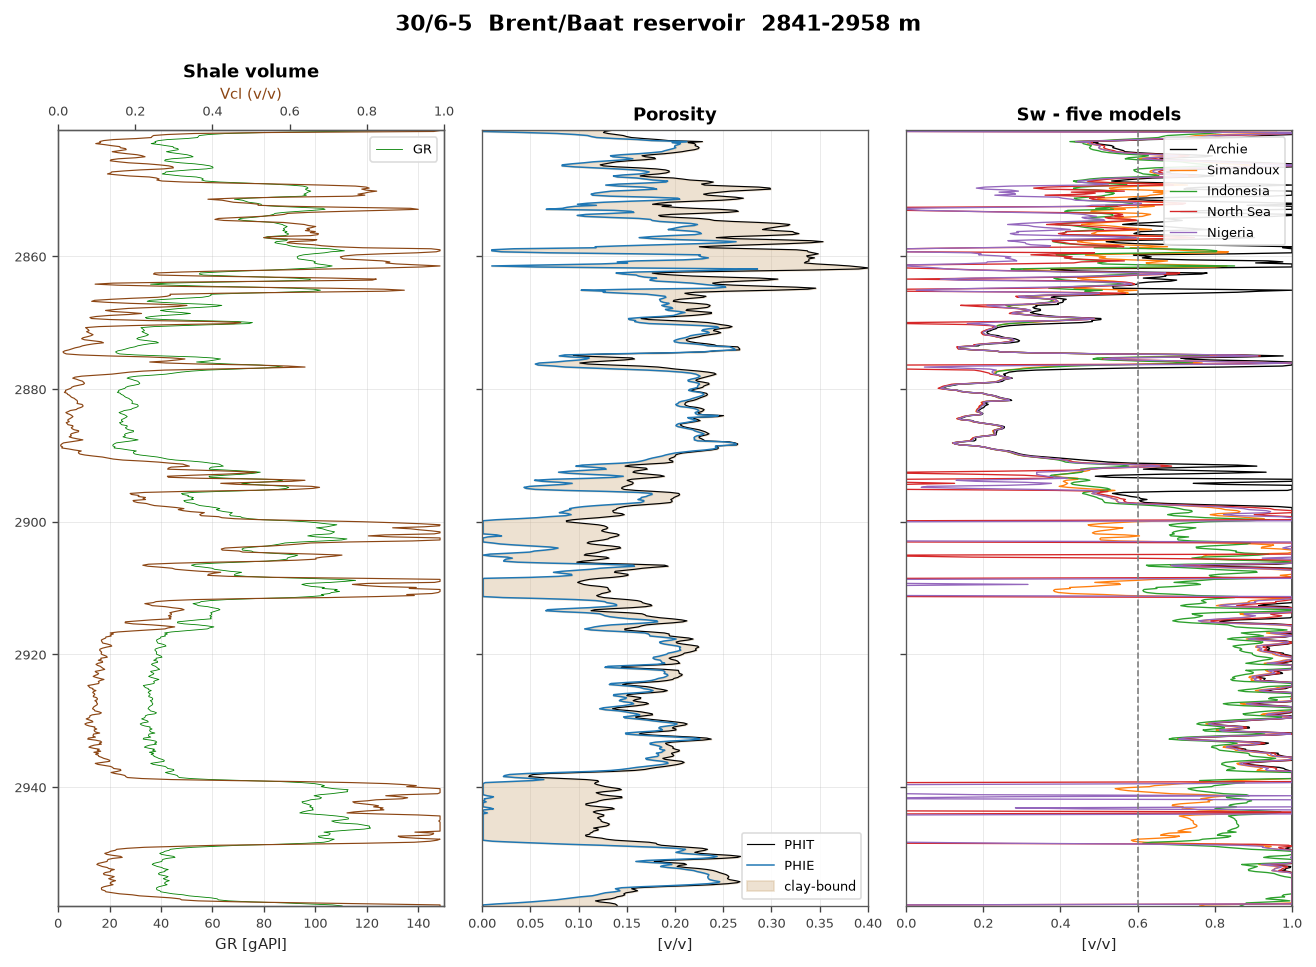

In [7]:
from petrophys.visualization import LogPlot

# Build a reservoir-interval well and attach the computed curves so the library
# LogPlot can render the composite. (GR is already on the sliced well.)
res_well = well.depth_slice(RES_TOP, RES_BOT)
res_well.add_curve("VCL",  vcl,  unit="v/v")
res_well.add_curve("PHIT", phit, unit="v/v")
res_well.add_curve("PHIE", phie, unit="v/v")
model_colors = dict(Archie="black", Simandoux="tab:orange", Indonesia="tab:green",
                    **{"North Sea": "tab:red", "Nigeria": "tab:purple"})
for name, sw in sw_base.items():
    res_well.add_curve("SW_" + name.replace("-", "_").upper(), sw, unit="v/v")

lp = LogPlot(res_well, figsize=(11, 8))
lp.create_figure(n_tracks=3)

# Track 1: GR + Vcl (Vcl on a twin axis)
lp.add_curve(0, "GR", color="green", xlim=(0, 150))
lp.axes[0].set_title("Shale volume")
ax0b = lp.axes[0].twiny()
ax0b.plot(vcl, res_well.depth, color="saddlebrown", lw=0.7)
ax0b.set_xlabel("Vcl (v/v)", color="saddlebrown"); ax0b.set_xlim(0, 1)

# Track 2: porosity (PHIT, PHIE, clay-bound fill)
lp.add_curve(1, "PHIT", color="black", linewidth=0.7, xlim=(0, 0.4), label="PHIT")
lp.add_curve(1, "PHIE", color="tab:blue", linewidth=0.9, xlim=(0, 0.4), label="PHIE")
lp.axes[1].fill_betweenx(res_well.depth, phie, phit, color="tan", alpha=0.4, label="clay-bound")
lp.axes[1].legend(loc="lower right", fontsize=8); lp.axes[1].set_title("Porosity")

# Track 3: Sw overlay of the 5 models
for name in sw_base:
    lp.add_curve(2, "SW_" + name.replace("-", "_").upper(), color=model_colors[name],
                 linewidth=0.8, xlim=(0, 1), label=name)
lp.axes[2].axvline(CUT["sw"], color="gray", ls="--", lw=1)
lp.axes[2].set_title("Sw - five models")

lp.set_depth_range()
lp.fig.suptitle("30/6-5  Brent/Baat reservoir  {:.0f}-{:.0f} m".format(RES_TOP, RES_BOT), y=0.995)
lp.show()


#### Reading the saturation track

Archie plots to the right of the shaly-sand models and therefore gives the
highest water saturation and least pay. That ordering is consistent with the
expected effect of unmodelled clay conductivity.


### 5.2 Figure - net pay and HCPT by model (the decision bar chart)

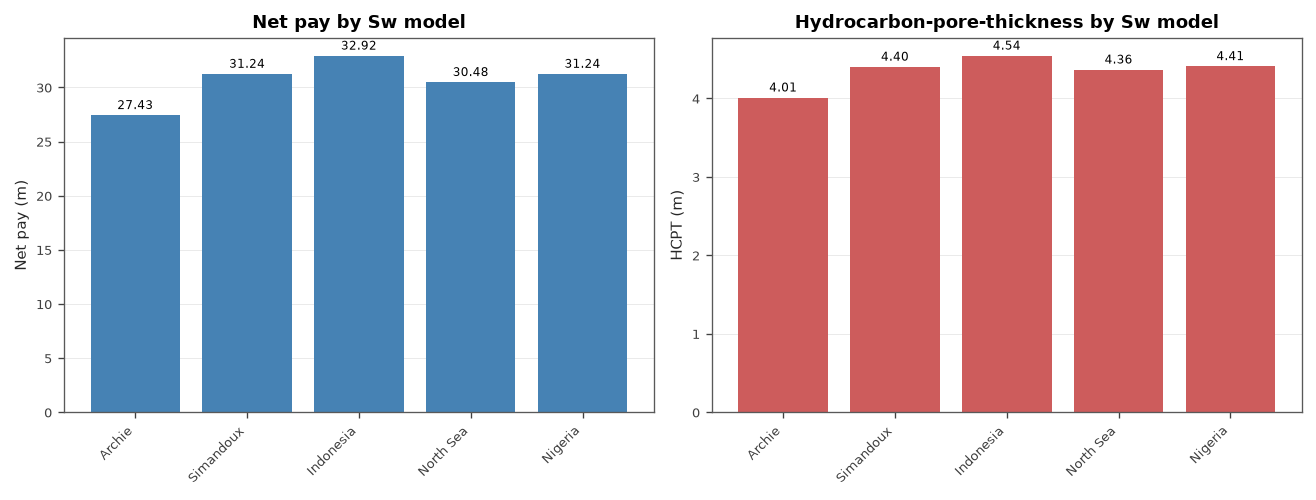

MODEL spread: net pay ranges 5.5 m, HCPT ranges 0.53 m
-> the choice of model alone moves HCPV by ~12%.


In [8]:
from petrophys.visualization import create_bar_comparison

names = list(decision.index)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

create_bar_comparison(names, decision["net_pay_thickness"].values, colors=["steelblue"] * len(names),
                      value_labels=True, ylabel="Net pay (m)",
                      title="Net pay by Sw model", ax=ax[0])
create_bar_comparison(names, decision["hcpt"].values, colors=["indianred"] * len(names),
                      value_labels=True, ylabel="HCPT (m)",
                      title="Hydrocarbon-pore-thickness by Sw model", ax=ax[1])

plt.tight_layout()
plt.show()

spread_np = decision["net_pay_thickness"].max() - decision["net_pay_thickness"].min()
spread_hc = decision["hcpt"].max() - decision["hcpt"].min()
print("MODEL spread: net pay ranges {:.1f} m, HCPT ranges {:.2f} m".format(spread_np, spread_hc))
print("-> the choice of model alone moves HCPV by ~{:.0f}%.".format(
    100*spread_hc/decision["hcpt"].median()))

### 5.3 Figure - model-vs-model Sw crossplot (Archie vs Indonesia)

If two models were interchangeable, points would lie on the 1:1 line. The systematic
departure below the line quantifies how much clay conductivity Archie mis-attributes to
water.

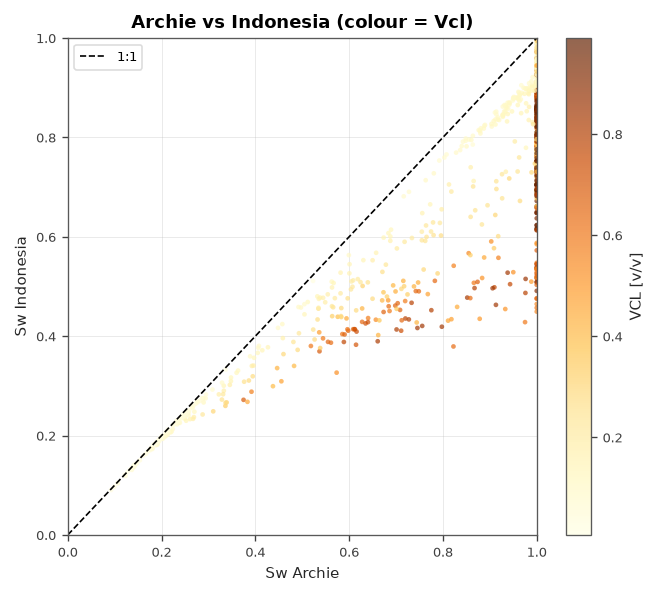

Mean Sw(Archie) - Sw(Indonesia) = +0.138


In [9]:
from petrophys.visualization import create_crossplot

# Archie vs Indonesia Sw crossplot, coloured by Vcl, rendered by the library
# crossplot. res_well already carries SW_ARCHIE, SW_INDONESIA and VCL.
cp = create_crossplot(
    res_well, "SW_ARCHIE", "SW_INDONESIA", color_curve="VCL",
    xlim=(0, 1), ylim=(0, 1), cmap="YlOrBr", marker_size=8, figsize=(5.6, 5),
    title="Archie vs Indonesia (colour = Vcl)",
)
cp.add_line([0, 1], [0, 1], color="black", linestyle="--", label="1:1")
cp.ax.set_xlabel("Sw Archie"); cp.ax.set_ylabel("Sw Indonesia")
cp.show()

sw_ar = sw_base["Archie"]; sw_in = sw_base["Indonesia"]
good = ~np.isnan(sw_ar) & ~np.isnan(sw_in)
dsw = float(np.nanmean(sw_ar[good] - sw_in[good]))
print("Mean Sw(Archie) - Sw(Indonesia) = {:+.3f}".format(dsw))


#### Crossplot interpretation

The points fall below the 1:1 line, so the Indonesia model returns lower water
saturation than Archie. The separation increases with Vcl, supporting clay
conductivity as the main cause of the model difference.


## Part 6 - Parameter sensitivity (the tornado)

The decision table captured **model** uncertainty. Now we quantify **parameter**
uncertainty for a single reference model. We use **Indonesia** as the reference - the robust
workhorse for dispersed shaly sands, and the model recommended in Part 7 - and sweep each
key input across a defensible low/high range while holding the others at base:

| Assumption | Low | Base | High | Why uncertain |
|---|---|---|---|---|
| Rw (ohm.m) | 0.05 | 0.070 | 0.09 | header basis needed reconciliation; 1981 vintage |
| m | 1.8 | 2.0 | 2.2 | operator value, but no SCAL of our own |
| n | 1.8 | 2.0 | 2.2 | no SCAL |
| Vcl cutoff | 0.30 | 0.40 | 0.50 | pay-flag choice (standard = 0.40) |

For each we record HCPT (and net pay) at low and high, and draw a **tornado**: the widest
bar is the assumption the answer is most sensitive to - i.e. where a measurement would buy
the most certainty. `parameter_sensitivity` (in `petrophys.evaluation`) does the
bookkeeping: it calls an evaluation once at base and twice per assumption, and returns
one row per assumption and output with `low`, `base`, `high` and `swing` (|high - low|),
widest swing first.

In [10]:
def pay_case(model="indonesia", Rw=BASE["Rw"], m=BASE["m"], n=BASE["n"], vcl_cut=CUT["vcl"]):
    """Pay summary of one model with some assumptions changed (the rest at base)."""
    run = compare_saturation_models(models=[model], rw=Rw, m=m, n=n, vcl_cutoff=vcl_cut, **COMMON)
    return run.pay[model]

sweeps = {
    "Rw":         ({"Rw": 0.05},       {"Rw": 0.09}),
    "m":          ({"m": 1.8},         {"m": 2.2}),
    "n":          ({"n": 1.8},         {"n": 2.2}),
    "Vcl cutoff": ({"vcl_cut": 0.30},  {"vcl_cut": 0.50}),
}
sens_all = parameter_sensitivity(pay_case, sweeps, outputs=["hcpt", "net_pay_thickness"])
base_hc = sens_all.attrs["base"]["hcpt"]
base_np = sens_all.attrs["base"]["net_pay_thickness"]
print("Indonesia BASE: net pay = {:.2f} m, HCPT = {:.3f} m".format(base_np, base_hc))
print()
print(sens_all[["output", "case", "low", "high", "swing"]].round(3).to_string(index=False))

sens = sens_all[sens_all["output"] == "hcpt"].reset_index(drop=True)   # the tornado ranks HCPT

Indonesia BASE: net pay = 32.92 m, HCPT = 4.542 m

           output       case    low   high  swing
             hcpt          m  5.082  4.057  1.025
             hcpt         Rw  5.043  4.176  0.867
             hcpt          n  4.872  4.259  0.613
             hcpt Vcl cutoff  4.307  4.819  0.513
net_pay_thickness          m 37.490 29.565  7.926
net_pay_thickness         Rw 36.576 30.480  6.096
net_pay_thickness Vcl cutoff 30.176 36.271  6.095
net_pay_thickness          n 34.747 31.547  3.200


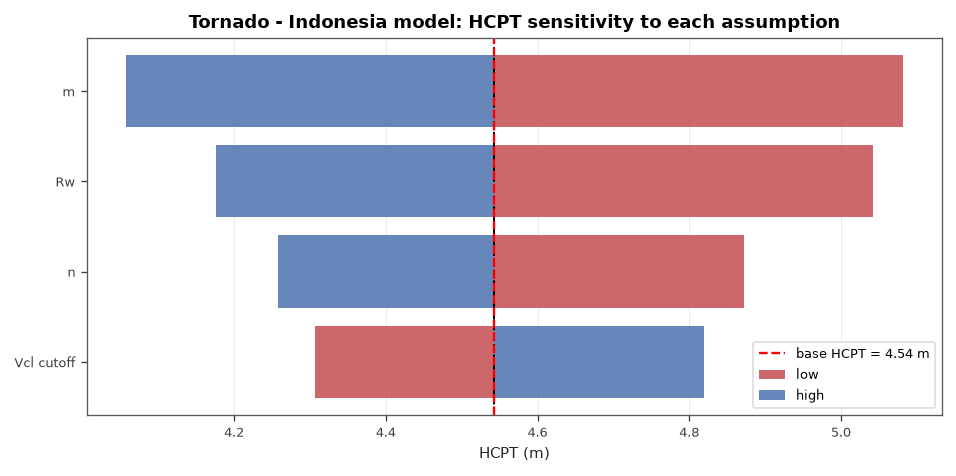

Assumptions ranked by HCPT span (widest first):
  1. m          span 1.02 m -> SCAL formation-factor tests on core plugs (m)
  2. Rw         span 0.87 m -> a produced- or formation-water sample (Rw)
  3. n          span 0.61 m -> SCAL resistivity-index tests on core plugs (n)
  4. Vcl cutoff span 0.51 m -> a core- or test-calibrated clay-volume cutoff
Most sensitive assumption: m - acquire SCAL formation-factor tests on core plugs (m) first.


In [11]:
from petrophys.visualization import create_tornado_plot

# Tornado: HCPT low/high outcome for each swept assumption about the base case,
# rendered by the library tornado plotter (it sorts widest-span to the top).
fig, ax = create_tornado_plot(
    sens["case"].tolist(),
    sens["low"].values,
    sens["high"].values,
    base=base_hc,
    xlabel="HCPT (m)",
    figsize=(8, 4),
    title="Tornado - Indonesia model: HCPT sensitivity to each assumption",
)
ax.axvline(base_hc, color="red", ls="--", lw=1.4, label="base HCPT = {:.2f} m".format(base_hc))
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

# The measurement that would pin down each assumption.
MEASUREMENT = {
    "Rw": "a produced- or formation-water sample (Rw)",
    "m": "SCAL formation-factor tests on core plugs (m)",
    "n": "SCAL resistivity-index tests on core plugs (n)",
    "Vcl cutoff": "a core- or test-calibrated clay-volume cutoff",
}
ranked = sens      # parameter_sensitivity already sorts by swing, widest first
print("Assumptions ranked by HCPT span (widest first):")
for i, row in ranked.iterrows():
    print("  {}. {:<10s} span {:.2f} m -> {}".format(
        i + 1, row["case"], row["swing"], MEASUREMENT[row["case"]]))
print("Most sensitive assumption: {} - acquire {} first.".format(
    ranked.loc[0, "case"], MEASUREMENT[ranked.loc[0, "case"]]))

#### Highest-value measurement

The widest bar is where a measurement buys the most certainty, and the ranking above names
it. The fix differs by lever: SCAL formation-factor tests pin down *m*, resistivity-index
tests pin down *n*, a water sample pins down Rw, and core or test data calibrate the clay
cutoff. Note how close the leading bars can be - a small change in the sweep ranges could
reorder them, so budget for the top two rather than only the first.

### 6.1 Combining model + parameter uncertainty into an HCPV band

To quote an honest range we combine both sources:

- **Low case**: the most pessimistic *model* (Archie) at its most pessimistic parameter
  corner.
- **High case**: the recommended model (Indonesia) at its most optimistic parameter
  corner - the upper edge of the band is **parameter-driven**, not model-driven.
- **Base case**: our recommended model at base parameters.

We express the band as HCPT and as a percentage around the recommended base.

In [12]:
# Recommended model = Indonesia (justified in Part 7). Build a combined band with
# pay_case from Part 6: one model and one parameter corner at a time.
rec = comparison.pay["indonesia"]                                             # base (recommended)
low = pay_case("archie", Rw=0.09, m=2.2, n=2.2, vcl_cut=0.30)                 # pessimistic corner
high = pay_case("indonesia", Rw=0.05, m=1.8, n=1.8, vcl_cut=0.50)             # optimistic corner
rec_np, rec_hc = rec.net_pay_thickness, rec.hcpt
low_hc, high_hc = low.hcpt, high.hcpt

band = pd.DataFrame([
    dict(Case="Low  (Archie, pessimistic params)",    Net_pay_m=round(low.net_pay_thickness, 2),  HCPT_m=round(low_hc, 3)),
    dict(Case="Base (Indonesia, base params)",        Net_pay_m=round(rec_np, 2),                 HCPT_m=round(rec_hc, 3)),
    dict(Case="High (Indonesia, optimistic params)",  Net_pay_m=round(high.net_pay_thickness, 2), HCPT_m=round(high_hc, 3)),
]).set_index("Case")
print(band.to_string())
print()
lo_pct = 100*(low_hc-rec_hc)/rec_hc
hi_pct = 100*(high_hc-rec_hc)/rec_hc
print("HCPV band vs base: {:+.0f}% / {:+.0f}%  (HCPT {:.2f} - {:.2f} m, base {:.2f} m)".format(
    lo_pct, hi_pct, low_hc, high_hc, rec_hc))

                                     Net_pay_m  HCPT_m
Case                                                  
Low  (Archie, pessimistic params)        20.57   2.927
Base (Indonesia, base params)            32.92   4.542
High (Indonesia, optimistic params)      55.17   6.927

HCPV band vs base: -36% / +52%  (HCPT 2.93 - 6.93 m, base 4.54 m)


## Part 7 - Recommendation & deliverable

**Recommended model: Indonesia (Poupon-Leveaux).**

Reasoning:

1. **The rock is shaly.** The mean Vcl printed in 4.1 is well above clean-sand levels, with
   dispersed clay. Archie ignores clay conductivity and reads the wettest of the five models -
   it *systematically undercounts pay* here (see the Archie-vs-Indonesia crossplot, where the
   gap grows with Vcl). Archie is the wrong tool for this interval and is kept only as a
   pessimistic bookend.

2. **Indonesia is the right shaly-sand workhorse.** Its `Vcl^(2-Vcl)` clay term is
   numerically stable across the full Vcl range (including the shales; the pay window itself
   is Vcl < 0.40) and does not require lab data we do not have. Simandoux tracks it closely
   but is less robust at high Vcl.

3. **The lab-data family was excluded, not guessed.** Waxman-Smits and Dual-Water
   need clay-specific laboratory inputs (CEC/Qv, Rwb, clay porosity) that this well
   does not have; running them on guesses produces answers that are only as good as
   the guesses (lesson 07, section 3b, demonstrates the failure mode). The two
   regional field-data forms take their place in the comparison - and the North Sea form
   (the local convention) landing close to Indonesia is useful corroboration. The quoted
   band keeps model uncertainty on the *low* side (the Archie bookend) with the upper edge
   parameter-driven (Indonesia at optimistic parameters).

4. **The shaly-sand models agree closely.** The cell below prints where Indonesia sits in the
   decision table and how far its HCPT is from the median of the four shaly-sand models. Their
   spread is small next to the Archie-vs-shaly-sand gap, so the choice *among* shaly-sand models
   matters much less than the choice to use one at all.

**Deliverable - the numbers with their uncertainty** are printed by the cell below: the
recommended base case, the combined model + parameter band, and the measurement to acquire first.

The honest headline for the team: *the shaly-sand correction moves HCPV materially versus
Archie, and the residual volumetric uncertainty is set mainly by the widest tornado bars.
Book the Indonesia base case, carry the band, and acquire the measurement for the widest bar
before committing volumes.*

In [13]:
shaly = decision.drop(index="Archie")
indo = decision.loc["Indonesia"]
hcpt_rank = int(decision["hcpt"].rank(ascending=False)["Indonesia"])
sw_rank = int(decision["mean_sw"].rank(ascending=False)["Indonesia"])
print("Indonesia in the five-model table: rank {} of {} by HCPT, rank {} of {} by mean Sw (wettest = 1)".format(
    hcpt_rank, len(decision), sw_rank, len(decision)))
print("Shaly-sand models: HCPT {:.2f}-{:.2f} m (spread {:.0f}% of their median); Archie {:.2f} m".format(
    shaly["hcpt"].min(), shaly["hcpt"].max(),
    100 * (shaly["hcpt"].max() - shaly["hcpt"].min()) / shaly["hcpt"].median(),
    decision.loc["Archie", "hcpt"]))
print("Indonesia HCPT vs shaly-sand median: {:+.1f}%".format(
    100 * (indo["hcpt"] - shaly["hcpt"].median()) / shaly["hcpt"].median()))
print()
print("DELIVERABLE")
print("  Recommended model : Indonesia, base parameters")
print("  Net pay / HCPT    : {:.1f} m / {:.2f} m".format(rec_np, rec_hc))
print("  HCPT band         : {:.2f} - {:.2f} m ({:+.0f}% / {:+.0f}% vs base)".format(
    low_hc, high_hc, lo_pct, hi_pct))
print("  Dominant levers   : {} (tornado order)".format(", ".join(ranked["case"].head(2))))
print("  Acquire first     : {}".format(MEASUREMENT[ranked.loc[0, "case"]]))

Indonesia in the five-model table: rank 1 of 5 by HCPT, rank 3 of 5 by mean Sw (wettest = 1)
Shaly-sand models: HCPT 4.36-4.54 m (spread 4% of their median); Archie 4.01 m
Indonesia HCPT vs shaly-sand median: +3.1%

DELIVERABLE
  Recommended model : Indonesia, base parameters
  Net pay / HCPT    : 32.9 m / 4.54 m
  HCPT band         : 2.93 - 6.93 m (-36% / +52% vs base)
  Dominant levers   : m, Rw (tornado order)
  Acquire first     : SCAL formation-factor tests on core plugs (m)


## Part 8a - Limitations & assumptions

Everything below was **assumed**, not measured, and each is a candidate for the next
data-acquisition dollar:

- **Rw = 0.070 ohm.m at 230 degF (reservoir temperature)** - documented (header +
  completion-report reconciliation, lesson 09) but not measured by us; the printed header
  basis was ambiguous and the evaluation is 1981 vintage. The tornado in Part 6 ranks how much
  it matters relative to m, n and the Vcl cutoff.
- **a = 0.80, m = 2.0, n = 2.0** - the operator's evaluation constants, adopted without
  SCAL of our own. The log-only Pickett regression on the water leg is unusable
  (unphysical slope, weak R-squared) and is kept only as the regression-trap
  demonstration.
- **No CEC / Rwb lab data** - the Waxman-Smits and Dual-Water family was therefore
  excluded from the comparison rather than run on guesses (the workflow router applies
  the same rule: it only selects Waxman-Smits when `cec` is supplied). The regional
  North Sea and Nigeria forms stand in as field-data alternatives.
- **GR endpoints** from interval percentiles, not a hand-picked clean/shale baseline (and
  clamped by the library's boundary rules - clean anchor <=20 API, shale anchor >=100 API;
  see 4.1).
- **Core SWC was not used** - the points counted in Part 2 sit inside the evaluated reservoir
  slice; a production study would benchmark the five models against them (with the flushing
  caveat on core saturations). Here the study stayed log-only for scope, so the model choice
  rests on physics and spread, not on a core match.
- **Fixed cutoff set** (Vcl 0.40 / PHIE 0.08 / Sw 0.60 - the clastic curriculum
  standards) - conventional rather than derived; the Vcl cutoff was included in the
  sensitivity so its effect is visible in the tornado.
- **HCPT is a per-well column index**, not a mapped HCPV - area/NTG closure comes from the
  static model, which is outside this lesson's scope.

## Part 8b - Appendix: reproduce on another well

To repeat this study on a different well, change the sample and the two intervals;
`evaluate_interval` and the library calls do the rest.

```python
w2 = pp.read(pp.sample("<well_id>"))               # e.g. another GeoLink well
res2 = evaluate_interval(w2, <res_top>, <res_bot>) # hydrocarbon interval
wat2 = evaluate_interval(w2, <wat_top>, <wat_bot>) # water leg for Pickett
# then re-run: pickett_analysis -> compare_saturation_models -> parameter_sensitivity
```

Guidance for a new well:
- Pick the **water leg** for Pickett from a zone you independently believe is Sw~1 - and
  verify that belief against sibling studies and any core data before trusting it (on this
  well, CS1's formation roll-up finds only scattered, low net-to-gross flags in the Statfjord
  and does not treat it as a target); if the fit is weak (low R-squared, m outside 1.6-2.1),
  treat it as illustrative and fall back to documented or basin-typical m/n as we did here.
- State the temperature of every Rw you use, and correct it to formation temperature
  wherever the interval is not at that temperature.
- Keep the **five-model** run and the **tornado** - the decision value is in the *spread*
  and in identifying the *most sensitive assumption*, not in any single deterministic Sw.

### Recap

- Five field-data saturation models ran on the Brent sands with one parameter set; Archie reads
  the wettest, and the four shaly-sand models agree closely with one another.
- A log-only Pickett regression on the Statfjord water leg is unusable here; the base case uses the
  operator's documented constants (Rw 0.070 ohm.m at 230 degF, a = 0.80, m = n = 2).
- The tornado ranks the parameter levers, and the widest bars name the measurement to acquire first.
- The deliverable is a recommended model (Indonesia), a base case and a combined model + parameter
  band on HCPT - not a single number.

### Exercises

1. **Widen the Rw sweep** to 0.04-0.10 ohm.m. Does the tornado order change? What does that tell you
   about how the sweep ranges drive the "most sensitive" answer?
2. **Benchmark against core.** Convert SWC to v/v (divide by 100), sample each model's Sw at the
   core depths, and compute the mean difference. Does the core support the Indonesia choice?
3. **Water-leg Rw.** The Statfjord is hotter than the Brent. Use the Arps relation to estimate Rw
   at the Statfjord from 0.070 ohm.m at 230 degF, and discuss how that affects the Pickett read-out.

### What's next

Compare with **CS1**, which interprets the same well in one `pp.interpret` call and uses the
workflow's auto-routed saturation model; the tornado here tells you which of CS1's settings to
challenge first.